# Eurovision B: зрители против жюри

Прогнозируем $Y=1$, если **место у зрителей выше места у жюри**.
Равенство мест даёт 0. Это вероятность события, а не прогноз общего победителя.

| Модель | Основа |
|---|---|
| M0 | Отдельная Beta–Bernoulli по истории каждой страны |
| M1 | Probit: эффект страны с фиксированным prior + признаки |
| M2 | Те же признаки; иерархические эффекты стран и общий intercept |

**2025 — отдельный тест; обучение и выбор настроек используют только прошлые годы.**
Модель B описывает отдельные бинарные события. Она не задаёт совместное
распределение двух полных рейтингов. Ошибки сравниваем по целым конкурсным годам.


In [4]:
%pip -q install "numpyro==0.19.0" "jax[cpu]==0.7.2" "arviz==0.22.0" openpyxl


In [5]:
from pathlib import Path
import hashlib
import json
import time
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MaxNLocator
from scipy.special import ndtr, log_ndtr, logsumexp
from scipy.stats import beta as beta_distribution
from IPython.display import display, Markdown

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
from jax.scipy.special import log_ndtr as jax_log_ndtr
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
import arviz as az

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/eurovision_features.xlsx").is_file())
DATA_PATH = ROOT / "data/eurovision_features.xlsx"
EXPERIMENT =  "matched_core"  # market / matched_core / full_core
OUTPUT_DIR = ROOT / "results/generated/task_b" / EXPERIMENT
HOLDOUT_YEAR = 2025
FIRST_TEST_YEAR = 2021
SEED = 20261025
MODELS = ("M0", "M1", "M2")
TARGET = "target_audience_above_jury"
COUNTRY_SD, BETA_SD, TAU_SD = 1.0, 0.5, 0.5
NUM_CHAINS, NUM_WARMUP, NUM_SAMPLES = 4, 1000, 1000
RUN_SENSITIVITY = True
MODEL_VERSION = "B-country-probit-v1"
CORE_FEATURES = [
    "running_position", "host", "english_only", "english_mixed", "bpm",
    "danceability", "dynamic_complexity", "log_word_count", "repetitiveness",
    "past_audience_advantage", "past_split_count",
]
BINARY_FEATURES = {"host", "english_only", "english_mixed"}
EXPERIMENTS = {
    "market": ("B С рынком", CORE_FEATURES + ["market_strength"]),
    "matched_core": ("B С рынком", CORE_FEATURES),
    "full_core": ("B Зрители и жюри", CORE_FEATURES),
}
if EXPERIMENT not in EXPERIMENTS:
    raise ValueError(f"Выберите эксперимент из {list(EXPERIMENTS)}")
SHEET, FEATURES = EXPERIMENTS[EXPERIMENT]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
COLORS = {"M0": "#65758A", "M1": "#3569B8", "M2": "#168B83"}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
pd.set_option("display.max_rows", 40)
pd.set_option("display.precision", 4)
print(f"NumPyro {numpyro.__version__}; JAX {jax.__version__}; ArviZ {az.__version__}")


NumPyro 0.19.0; JAX 0.7.2; ArviZ 0.22.0


## 1. Данные

По умолчанию включён `market_strength`. `matched_core` исключает котировки
на тех же наблюдениях; `full_core` читает основной лист B.
Охват B — 2016–2025 без 2020. Время архивных котировок неизвестно — принятое ограничение.
Стандартизацию рассчитываем только на train; индикаторы 0/1 не масштабируем.


In [6]:
if not DATA_PATH.is_file():
    raise FileNotFoundError("Укажите путь к Excel в DATA_PATH.")
raw = pd.read_excel(DATA_PATH, sheet_name=SHEET)
required = ["year", "country", TARGET] + FEATURES
if not set(required) <= set(raw.columns):
    raise ValueError(f"Не хватает столбцов: {sorted(set(required)-set(raw.columns))}")
assert not raw[required].isna().any().any()
assert not raw.duplicated(["year", "country"]).any()
assert raw[TARGET].isin([0, 1]).all()
assert np.isfinite(raw[FEATURES].to_numpy(float)).all()
assert set(raw.year) == set(range(2016, HOLDOUT_YEAR + 1)) - {2020}
for col in BINARY_FEATURES:
    assert raw[col].isin([0, 1]).all(), col
development = raw.loc[raw.year.lt(HOLDOUT_YEAR)].copy()
holdout_design = raw.loc[raw.year.eq(HOLDOUT_YEAR), ["year", "country"] + FEATURES].copy()
holdout_truth = raw.loc[raw.year.eq(HOLDOUT_YEAR), ["year", "country", TARGET]].copy()
DEV_YEARS = sorted(int(y) for y in development.year.unique() if y >= FIRST_TEST_YEAR)
assert DEV_YEARS == [2021, 2022, 2023, 2024]


def prepare_fold(train, design):
    assert train.year.max() < design.year.min() <= HOLDOUT_YEAR
    assert train.year.max() < HOLDOUT_YEAR
    assert TARGET not in design.columns
    train = train.sort_values(["year", "country"]).copy()
    test = design.sort_values("country").reset_index(drop=True).copy()
    countries = sorted(train.country.unique())
    index = {c: i for i, c in enumerate(countries)}
    mean = train[FEATURES].mean()
    scale = train[FEATURES].std(ddof=0).replace(0, 1)
    mean.loc[list(BINARY_FEATURES)] = 0
    scale.loc[list(BINARY_FEATURES)] = 1
    return dict(train=train, test=test, countries=countries, index=index,
                X=((train[FEATURES]-mean)/scale).to_numpy(float),
                country_idx=train.country.map(index).to_numpy(int),
                y=train[TARGET].to_numpy(int),
                x_test=((test[FEATURES]-mean)/scale).to_numpy(float),
                mean=mean, scale=scale)


display(raw.groupby("year")[TARGET].agg(n="size", audience_above_jury="sum"))
print("Тестовые годы до 2025:", DEV_YEARS)
print("Признаки M1/M2:", ", ".join(FEATURES))


,n,audience_above_jury
year,,
2016,26,14
2017,26,15
2018,26,13
2019,26,12
2021,26,12
2022,25,12
2023,26,12
2024,25,11
2025,26,13


Тестовые годы до 2025: [2021, 2022, 2023, 2024]
Признаки M1/M2: running_position, host, english_only, english_mixed, bpm, danceability, dynamic_complexity, log_word_count, repetitiveness, past_audience_advantage, past_split_count


## 2. M0: история каждой страны

Как в решённом HA1, отдельно для страны $c$:
$$\theta_c\sim Beta(1,1),\quad
\theta_c\mid H\sim Beta(1+s_c,1+n_c-s_c).$$
Прогноз $P(Y_c=1\mid H)=(s_c+1)/(n_c+2)$.
У новой страны вероятность 0.5; отсутствие участия не считается проигрышем.
Posterior и его интервалы считаем точно, без MCMC.


In [7]:
def forecast_m0(fold, prior_concentration=1.0):
    history = fold["train"].groupby("country")[TARGET].agg(["sum", "count"])
    aligned = history.reindex(fold["test"].country).fillna(0)
    a = prior_concentration + aligned["sum"].to_numpy(float)
    b = prior_concentration + (aligned["count"]-aligned["sum"]).to_numpy(float)
    p = a/(a+b)
    out = fold["test"][["year", "country"]].copy()
    out["model"] = "M0"
    out["p"] = p
    out["p_q05"] = beta_distribution.ppf(0.05, a, b)
    out["p_q95"] = beta_distribution.ppf(0.95, a, b)
    out["log_p1"], out["log_p0"] = np.log(p), np.log1p(-p)
    out["mcse_p"] = 0.0
    out["train_end"] = int(fold["train"].year.max())
    out["history_n"] = aligned["count"].to_numpy(int)
    return out


## 3. M1 и M2: Bayesian probit

$$P(Y_i=1\mid\eta_i)=\Phi(\eta_i).$$
**M1:** $\eta_i=a_{c(i)}+x_i^\top\beta$, $a_c\sim N(0,1)$.
При отсутствии признаков $\Phi(a_c)\sim Uniform(0,1)$: это тот же prior, что у M0.

**M2:** $\eta_i=\alpha+a_{c(i)}+x_i^\top\beta$,
$\alpha\sim N(0,1)$, $a_c=\tau(z_c-\bar z)$,
$z_c\sim N(0,1)$, $\tau\sim HalfNormal(0.5)$.
Для обеих моделей $\beta_j\sim N(0,0.5^2)$ после стандартизации.
Используем устойчивый `log_ndtr`, как в HA3, и NUTS с нецентрированной иерархией из HA4.


In [8]:
def probit_model(X, country_idx, y, n_countries, model_id, prior_multiplier=1.0):
    z = numpyro.sample("z", dist.Normal(0, 1).expand([n_countries]).to_event(1))
    if model_id == "M2":
        alpha = numpyro.sample("alpha", dist.Normal(0, prior_multiplier))
        tau = numpyro.sample("tau", dist.HalfNormal(TAU_SD * prior_multiplier))
        a = numpyro.deterministic("a", tau * (z-z.mean()))
    elif model_id == "M1":
        alpha = 0.0
        a = numpyro.deterministic("a", COUNTRY_SD * prior_multiplier * z)
    else:
        raise ValueError(model_id)
    beta = numpyro.sample("beta", dist.Normal(0, BETA_SD * prior_multiplier)
                          .expand([X.shape[-1]]).to_event(1))
    eta = alpha + a[country_idx] + X @ beta
    numpyro.factor("outcomes", jnp.where(y == 1, jax_log_ndtr(eta), jax_log_ndtr(-eta)).sum())


def predictive_eta(samples, fold, model_id, rng, prior_multiplier=1.0):
    z = samples["z"]
    eta = np.empty(z.shape[:2] + (len(fold["test"]),))
    for j, country in enumerate(fold["test"].country):
        effect = (z[..., fold["index"][country]] if country in fold["index"]
                  else rng.normal(size=z.shape[:2]))
        if model_id == "M2":
            eta[..., j] = samples["alpha"] + samples["tau"]*(effect-z.mean(axis=-1))
        else:
            eta[..., j] = COUNTRY_SD * prior_multiplier * effect
    return eta + np.einsum("cdp,np->cdn", samples["beta"], fold["x_test"])


## 4. Обучение и проверка сходимости

Четыре цепи. Требуем R-hat ≤ 1.01, bulk ESS ≥ 400, tail ESS ≥ 200,
отсутствие divergences и достижений предельной глубины дерева.
При проблеме один раз увеличиваем длину расчёта и точность интегратора;
повторная неудача останавливает обучение с сохранённой диагностикой.
У M0 аналитическое решение: R-hat и ESS ей не нужны.


In [9]:
def fit_posterior(fold, model_id, seed, prior_multiplier=1.0):
    settings = dict(model=model_id, prior_multiplier=prior_multiplier,
                    features=FEATURES, countries=fold["countries"], seed=int(seed),
                    country_sd=COUNTRY_SD, beta_sd=BETA_SD, tau_sd=TAU_SD,
                    chains=NUM_CHAINS, warmup=NUM_WARMUP, samples=NUM_SAMPLES,
                    model_version=MODEL_VERSION, numpyro=numpyro.__version__, jax=jax.__version__)
    signature = hashlib.sha256(json.dumps(settings, sort_keys=True).encode())
    signature.update(probit_model.__code__.co_code)
    signature.update(repr(probit_model.__code__.co_consts).encode())
    for key in ("X", "country_idx", "y"):
        signature.update(np.ascontiguousarray(fold[key]).tobytes())
    stem = f"{model_id}_{fold['test'].year.iloc[0]}_{signature.hexdigest()[:16]}"
    cache = OUTPUT_DIR / "posterior"
    cache.mkdir(exist_ok=True)
    npz, meta = cache / f"{stem}.npz", cache / f"{stem}.json"
    if npz.exists() and meta.exists():
        report = json.loads(meta.read_text())
        if report["passed"]:
            report["prior_multiplier"] = float(prior_multiplier)
            print(f"  {model_id}: проверенный posterior из сохранённого расчёта", flush=True)
            with np.load(npz, allow_pickle=False) as loaded:
                return {k: loaded[k] for k in loaded.files}, report
    for attempt in range(2):
        print(f"  {model_id}: NUTS, попытка {attempt + 1}", flush=True)
        kernel = NUTS(probit_model, target_accept_prob=0.95 if attempt == 0 else 0.99,
                      max_tree_depth=10 if attempt == 0 else 12)
        mcmc = MCMC(kernel, num_warmup=NUM_WARMUP * (attempt + 1),
                    num_samples=NUM_SAMPLES * (attempt + 1), num_chains=NUM_CHAINS,
                    chain_method="sequential", progress_bar=True)
        started = time.perf_counter()
        mcmc.run(jax.random.PRNGKey(seed + attempt),
                 jnp.asarray(fold["X"]), jnp.asarray(fold["country_idx"]),
                 jnp.asarray(fold["y"]), len(fold["countries"]), model_id,
                 prior_multiplier, extra_fields=("diverging", "num_steps"))
        samples = {k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()}
        extra = mcmc.get_extra_fields(group_by_chain=True)
        diag = az.summary(az.from_dict(posterior=samples), kind="diagnostics", round_to=6)
        diag.to_csv(cache / f"{stem}_diagnostics.csv")
        depth_limit = 2 ** (10 if attempt == 0 else 12) - 1
        report = dict(model=model_id, year=int(fold["test"].year.iloc[0]),
                      prior_multiplier=float(prior_multiplier),
                      train_start=int(fold["train"].year.min()),
                      train_end=int(fold["train"].year.max()),
                      rhat_max=float(diag.r_hat.max()),
                      ess_bulk_min=float(diag.ess_bulk.min()),
                      ess_tail_min=float(diag.ess_tail.min()),
                      divergences=int(np.asarray(extra["diverging"]).sum()),
                      max_depth_hits=int((np.asarray(extra["num_steps"]) >= depth_limit).sum()),
                      seconds=time.perf_counter() - started, attempt=attempt + 1)
        report["passed"] = bool(
            np.isfinite(diag[["r_hat", "ess_bulk", "ess_tail"]]).all().all()
            and report["rhat_max"] <= 1.01 and report["ess_bulk_min"] >= 400
            and report["ess_tail_min"] >= 200 and report["divergences"] == 0
            and report["max_depth_hits"] == 0)
        meta.write_text(json.dumps(report, indent=2), encoding="utf-8")
        print(" ", report, flush=True)
        if report["passed"]:
            np.savez_compressed(npz, **samples)
            return samples, report
    raise RuntimeError(f"{model_id}: диагностика не пройдена. См. {cache / stem}")


def forecast_probit(samples, fold, model_id, seed, prior_multiplier=1.0):
    eta = predictive_eta(samples, fold, model_id, np.random.default_rng(seed), prior_multiplier)
    p_draw = ndtr(eta)
    out = fold["test"][["year", "country"]].copy()
    out["model"] = model_id
    out["p"] = p_draw.mean(axis=(0, 1))
    out["p_q05"], out["p_q95"] = np.quantile(p_draw.reshape(-1, p_draw.shape[-1]), [0.05, 0.95], axis=0)
    # Сначала среднее вероятностей по posterior, затем логарифм.
    out["log_p1"] = logsumexp(log_ndtr(eta), axis=(0, 1))-np.log(eta.shape[0]*eta.shape[1])
    out["log_p0"] = logsumexp(log_ndtr(-eta), axis=(0, 1))-np.log(eta.shape[0]*eta.shape[1])
    out["mcse_p"] = az.mcse(az.from_dict(posterior={"p": p_draw}), method="mean").p.values
    out["train_end"] = int(fold["train"].year.max())
    assert np.isfinite(out.select_dtypes("number")).all().all()
    assert out.p.between(0, 1).all()
    if out.mcse_p.max() > 0.01:
        warnings.warn("MCSE вероятности выше 0.01; увеличьте NUM_SAMPLES для большей точности.")
    return out


def score_forecast(prediction, truth):
    joined = prediction.merge(truth, on=["year", "country"], validate="one_to_one")
    assert len(joined) == len(prediction)
    y = joined[TARGET].to_numpy(int)
    return dict(model=prediction.model.iloc[0], year=int(prediction.year.iloc[0]),
                n=len(joined), brier=float(np.mean((joined.p.to_numpy()-y)**2)),
                log_loss=float(-np.mean(np.where(y == 1, joined.log_p1, joined.log_p0))))


def run_year(model_id, train, design, seed, prior_multiplier=1.0, m0_concentration=1.0):
    fold = prepare_fold(train, design)
    if model_id == "M0":
        prediction = forecast_m0(fold, m0_concentration)
        return dict(prediction=prediction, fold=fold, samples=None,
                    diagnostic=dict(model="M0", year=int(design.year.iloc[0]),
                                    train_end=int(train.year.max()), passed=True,
                                    method="exact_Beta_Bernoulli", prior_concentration=m0_concentration))
    samples, diagnostic = fit_posterior(fold, model_id, seed, prior_multiplier)
    prediction = forecast_probit(samples, fold, model_id, seed+100_000, prior_multiplier)
    return dict(prediction=prediction, fold=fold, samples=samples, diagnostic=diagnostic)


## 5. Проверки и prior predictive

Проверяем запрет тестовых меток в design, стандартизацию только по train,
точный прогноз M0 и его поведение для новой страны. Для priors смотрим,
как часто они задают вероятности выше 95% или ниже 5%, до обучения.


In [10]:
check = prepare_fold(development, holdout_design)
changed = holdout_design.copy()
changed["bpm"] += 10_000
assert np.array_equal(check["X"], prepare_fold(development, changed)["X"])
assert check["train"].year.max() == 2024 and TARGET not in check["test"]
assert check["mean"].loc[list(BINARY_FEATURES)].eq(0).all()
assert check["scale"].loc[list(BINARY_FEATURES)].eq(1).all()
toy = dict(train=pd.DataFrame({"year": [2021, 2022, 2023], "country": ["AA", "AA", "AA"], TARGET: [1, 1, 0]}),
           test=pd.DataFrame({"year": [2025, 2025], "country": ["AA", "NEW"]}))
assert np.allclose(forecast_m0(toy).p, [3/5, 1/2])
assert np.allclose(np.logaddexp(log_ndtr(np.array([-30., 0., 30.])),
                               log_ndtr(-np.array([-30., 0., 30.]))), 0)
first_year = DEV_YEARS[0]
prior_fold = prepare_fold(development.loc[development.year.lt(first_year)],
                         development.loc[development.year.eq(first_year), ["year", "country"]+FEATURES])
prior_rows = []
for i, model_id in enumerate(MODELS):
    rng = np.random.default_rng(SEED+i)
    if model_id == "M0":
        p = rng.beta(1, 1, size=(2000, len(prior_fold["test"])))
    else:
        samples = {"z": rng.normal(size=(1, 2000, len(prior_fold["countries"]))),
                   "beta": rng.normal(0, BETA_SD, size=(1, 2000, len(FEATURES)))}
        if model_id == "M2":
            samples.update(alpha=rng.normal(size=(1, 2000)),
                           tau=np.abs(rng.normal(0, TAU_SD, size=(1, 2000))))
        p = ndtr(predictive_eta(samples, prior_fold, model_id, rng))
    prior_rows.append(dict(model=model_id, mean_probability=p.mean(),
                           share_below_5=np.mean(p < 0.05), share_above_95=np.mean(p > 0.95)))
prior_predictive = pd.DataFrame(prior_rows)
display(prior_predictive.round(4))
print("Проверки реализации: OK")


,model,mean_probability,share_below_5,share_above_95
0,M0,0.5018,0.0489,0.0508
1,M1,0.4977,0.1972,0.1939
2,M2,0.5035,0.2026,0.2051


Проверки реализации: OK


## 6. Проверка на прошлых годах

Для 2021–2024 выпускаем прогноз по всем предыдущим годам.
Все модели получают одинаковые наблюдения. Brier и бинарный log loss:
**меньше — лучше**. Каждый конкурс имеет одинаковый вес.
Число успешных участников не фиксировано; вероятности не обязаны суммироваться в 1.


In [11]:
development_runs, development_scores, diagnostics = {}, [], []
for year in DEV_YEARS:
    train = development.loc[development.year.lt(year)]
    design = development.loc[development.year.eq(year), ["year", "country"]+FEATURES]
    truth = development.loc[development.year.eq(year), ["year", "country", TARGET]]
    print(f"\nПроверка {year}: train {train.year.min()}–{train.year.max()}", flush=True)
    for i, model_id in enumerate(MODELS):
        run = run_year(model_id, train, design, SEED+year*10+i)
        development_runs[(year, model_id)] = run
        development_scores.append(score_forecast(run["prediction"], truth))
        diagnostics.append(run["diagnostic"])
dev_metrics = pd.DataFrame(development_scores)
dev_summary = dev_metrics.groupby("model")[["brier", "log_loss"]].mean()
display(dev_summary.round(4))



Проверка 2021: train 2016–2019
  M1: NUTS, попытка 1


sample: 100%|██████████| 2000/2000 [00:03<00:00, 646.14it/s, 15 steps of size 2.03e-01. acc. prob=0.97]


  {'model': 'M1', 'year': 2021, 'prior_multiplier': 1.0, 'train_start': 2016, 'train_end': 2019, 'rhat_max': 1.003036, 'ess_bulk_min': 3322.689429, 'ess_tail_min': 2438.061724, 'divergences': 0, 'max_depth_hits': 0, 'seconds': 37.98166646799973, 'attempt': 1, 'passed': True}
  M2: NUTS, попытка 1


sample: 100%|██████████| 2000/2000 [00:04<00:00, 463.62it/s, 15 steps of size 2.23e-01. acc. prob=0.94]


  {'model': 'M2', 'year': 2021, 'prior_multiplier': 1.0, 'train_start': 2016, 'train_end': 2019, 'rhat_max': 1.00775, 'ess_bulk_min': 876.550092, 'ess_tail_min': 1347.616528, 'divergences': 0, 'max_depth_hits': 0, 'seconds': 24.493131359000017, 'attempt': 1, 'passed': True}

Проверка 2022: train 2016–2021
  M1: NUTS, попытка 1


sample: 100%|██████████| 2000/2000 [00:02<00:00, 691.50it/s, 15 steps of size 2.50e-01. acc. prob=0.96]


... (8 outputs left out)

  {'model': 'M1', 'year': 2024, 'prior_multiplier': 1.0, 'train_start': 2016, 'train_end': 2023, 'rhat_max': 1.00388, 'ess_bulk_min': 2659.20693, 'ess_tail_min': 2410.692248, 'divergences': 0, 'max_depth_hits': 0, 'seconds': 22.561738030000015, 'attempt': 1, 'passed': True}
  M2: NUTS, попытка 1


sample: 100%|██████████| 2000/2000 [00:05<00:00, 356.70it/s, 31 steps of size 1.42e-01. acc. prob=0.96]


  {'model': 'M2', 'year': 2024, 'prior_multiplier': 1.0, 'train_start': 2016, 'train_end': 2023, 'rhat_max': 1.008101, 'ess_bulk_min': 640.1516, 'ess_tail_min': 1204.474959, 'divergences': 0, 'max_depth_hits': 0, 'seconds': 30.19535160400028, 'attempt': 1, 'passed': True}


,brier,log_loss
model,,
M0,0.1955,0.5750
M1,0.2165,0.6227
M2,0.2202,0.6350


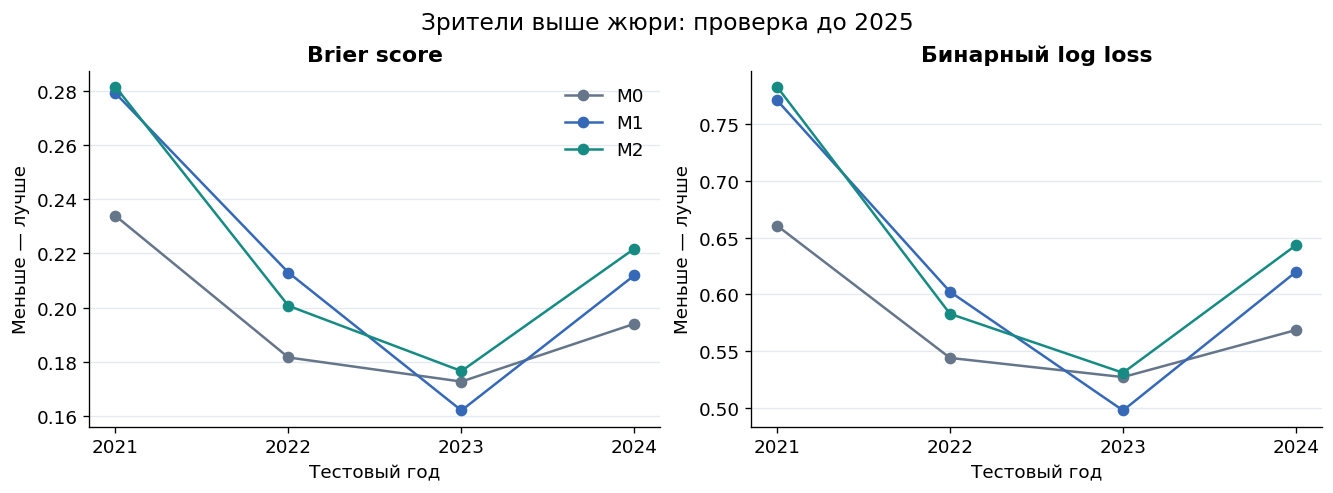

,comparison,metric,mean_difference,q025,q975,n_years
0,M1 − M0,brier,0.0210,-0.0002,0.0385,4
1,M2 − M1,brier,0.0036,-0.0068,0.0122,4
2,M1 − M0,log_loss,0.0477,-0.0075,0.0958,4
3,M2 − M1,log_loss,0.0123,-0.0087,0.0284,4


Отрицательная разница — улучшение. Интервалы по четырём годам ориентировочные.


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for model_id in MODELS:
    g = dev_metrics.loc[dev_metrics.model.eq(model_id)]
    for ax, metric in zip(axes, ["brier", "log_loss"]):
        ax.plot(g.year, g[metric], "o-", color=COLORS[model_id], label=model_id)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(axis="y", color="#E5EAF1")
axes[0].set(title="Brier score", xlabel="Тестовый год", ylabel="Меньше — лучше")
axes[1].set(title="Бинарный log loss", xlabel="Тестовый год", ylabel="Меньше — лучше")
axes[0].legend(frameon=False)
fig.suptitle("Зрители выше жюри: проверка до 2025", fontsize=14)
fig.savefig(OUTPUT_DIR / "development_scores.png", dpi=200, bbox_inches="tight")
plt.show()
paired_rows = []
for metric in ["brier", "log_loss"]:
    pivot = dev_metrics.pivot(index="year", columns="model", values=metric)
    for newer, older in [("M1", "M0"), ("M2", "M1")]:
        delta = (pivot[newer]-pivot[older]).to_numpy()
        bootstrap = np.random.default_rng(SEED).choice(delta, size=(10_000, len(delta)), replace=True).mean(axis=1)
        lo, hi = np.quantile(bootstrap, [0.025, 0.975])
        paired_rows.append(dict(comparison=f"{newer} − {older}", metric=metric,
                                mean_difference=delta.mean(), q025=lo, q975=hi, n_years=len(delta)))
paired_comparisons = pd.DataFrame(paired_rows)
display(paired_comparisons.round(4))
print("Отрицательная разница — улучшение. Интервалы по четырём годам ориентировочные.")


## 7. Чувствительность priors

Проверяем только 2024. Для M1/M2 удваиваем масштабы priors;
для M0 отдельно сравниваем Beta(1,1) и Beta(0.5,0.5).
Это разные проверки prior, не одинаковое преобразование для всех моделей.
Основной прогноз 2025 использует исходные priors.


In [13]:
sensitivity_rows = []
if RUN_SENSITIVITY:
    year = DEV_YEARS[-1]
    train = development.loc[development.year.lt(year)]
    design = development.loc[development.year.eq(year), ["year", "country"]+FEATURES]
    truth = development.loc[development.year.eq(year), ["year", "country", TARGET]]
    for i, model_id in enumerate(MODELS):
        run = run_year(model_id, train, design, SEED+year*10+i,
                       prior_multiplier=2.0, m0_concentration=0.5)
        row = score_forecast(run["prediction"], truth)
        row["prior"] = "Beta(0.5,0.5)" if model_id == "M0" else "scales_2x"
        sensitivity_rows.append(row)
        diagnostics.append(run["diagnostic"])
    sensitivity = pd.concat([dev_metrics.loc[dev_metrics.year.eq(year)].assign(prior="original"),
                             pd.DataFrame(sensitivity_rows)], ignore_index=True)
    display(sensitivity[["model", "prior", "brier", "log_loss"]].round(4))


  M1: NUTS, попытка 1


sample: 100%|██████████| 2000/2000 [00:03<00:00, 502.78it/s, 15 steps of size 2.28e-01. acc. prob=0.95]


  {'model': 'M1', 'year': 2024, 'prior_multiplier': 2.0, 'train_start': 2016, 'train_end': 2023, 'rhat_max': 1.003886, 'ess_bulk_min': 983.301515, 'ess_tail_min': 1542.20363, 'divergences': 0, 'max_depth_hits': 0, 'seconds': 21.12398523999991, 'attempt': 1, 'passed': True}
  M2: NUTS, попытка 1


sample: 100%|██████████| 2000/2000 [00:05<00:00, 384.33it/s, 15 steps of size 2.05e-01. acc. prob=0.93]


  {'model': 'M2', 'year': 2024, 'prior_multiplier': 2.0, 'train_start': 2016, 'train_end': 2023, 'rhat_max': 1.005063, 'ess_bulk_min': 522.869951, 'ess_tail_min': 883.903446, 'divergences': 0, 'max_depth_hits': 0, 'seconds': 32.54691726600004, 'attempt': 1, 'passed': True}


,model,prior,brier,log_loss
0,M0,original,0.1940,0.5685
1,M1,original,0.2119,0.6198
2,M2,original,0.2218,0.6434
3,M0,"Beta(0.5,0.5)",0.1971,0.5713
4,M1,scales_2x,0.2254,0.6633
5,M2,scales_2x,0.2231,0.6491


## 8. Финальный тест: 2025

Обучаемся на 2016–2024, затем присоединяем фактические исходы 2025.
Интервалы 5–95% описывают неопределённость вероятности события, а не итогового места.
MCSE — отдельная вычислительная погрешность. У аналитической M0 она равна нулю.


In [14]:
holdout_runs, holdout_scores = {}, []
for i, model_id in enumerate(MODELS):
    print(f"\nФинальный тест 2025: {model_id}", flush=True)
    run = run_year(model_id, development, holdout_design, SEED+HOLDOUT_YEAR*10+i)
    holdout_runs[model_id] = run
    holdout_scores.append(score_forecast(run["prediction"], holdout_truth))
    diagnostics.append(run["diagnostic"])
holdout_metrics = pd.DataFrame(holdout_scores).set_index("model")
predictions_2025 = pd.concat([r["prediction"] for r in holdout_runs.values()], ignore_index=True)
comparison_2025 = predictions_2025.merge(holdout_truth, on=["year", "country"], validate="many_to_one")
display(holdout_metrics.round(4))
table_2025 = comparison_2025.pivot(index="country", columns="model", values="p")
table_2025 = table_2025.join(holdout_truth.set_index("country")[TARGET]).sort_values("M2", ascending=False)
display(table_2025.style.format({m: "{:.1%}" for m in MODELS}))



Финальный тест 2025: M0

Финальный тест 2025: M1
  M1: NUTS, попытка 1


sample: 100%|██████████| 2000/2000 [00:03<00:00, 550.62it/s, 15 steps of size 2.48e-01. acc. prob=0.96]


  {'model': 'M1', 'year': 2025, 'prior_multiplier': 1.0, 'train_start': 2016, 'train_end': 2024, 'rhat_max': 1.00501, 'ess_bulk_min': 2165.186577, 'ess_tail_min': 2361.321775, 'divergences': 0, 'max_depth_hits': 0, 'seconds': 25.623650423000072, 'attempt': 1, 'passed': True}

Финальный тест 2025: M2
  M2: NUTS, попытка 1


sample: 100%|██████████| 2000/2000 [00:07<00:00, 284.29it/s, 31 steps of size 1.53e-01. acc. prob=0.97]


  {'model': 'M2', 'year': 2025, 'prior_multiplier': 1.0, 'train_start': 2016, 'train_end': 2024, 'rhat_max': 1.006007, 'ess_bulk_min': 847.221544, 'ess_tail_min': 1434.944417, 'divergences': 0, 'max_depth_hits': 0, 'seconds': 31.632110705000287, 'attempt': 1, 'passed': True}


,year,n,brier,log_loss
model,,,,
M0,2025,26,0.1598,0.4953
M1,2025,26,0.1765,0.5275
M2,2025,26,0.1752,0.5277


,M0,M1,M2,target_audience_above_jury
country,,,,
FI,85.7%,82.3%,79.0%,1
AL,50.0%,67.7%,74.8%,1
DE,50.0%,69.7%,71.8%,1
PL,83.3%,75.4%,69.8%,1
LT,75.0%,67.3%,67.1%,1
LV,50.0%,58.5%,66.4%,0
SE,30.0%,54.0%,65.3%,1
UA,77.8%,60.2%,56.8%,1
NO,66.7%,51.1%,55.9%,1


## 9. Прогноз и факт

Цвет фона показывает фактический исход. Точки — вероятности моделей;
горизонтальные линии — 90% posterior intervals для M2.
Порог 50% показан для ориентира; основные метрики оценивают вероятности без порога.


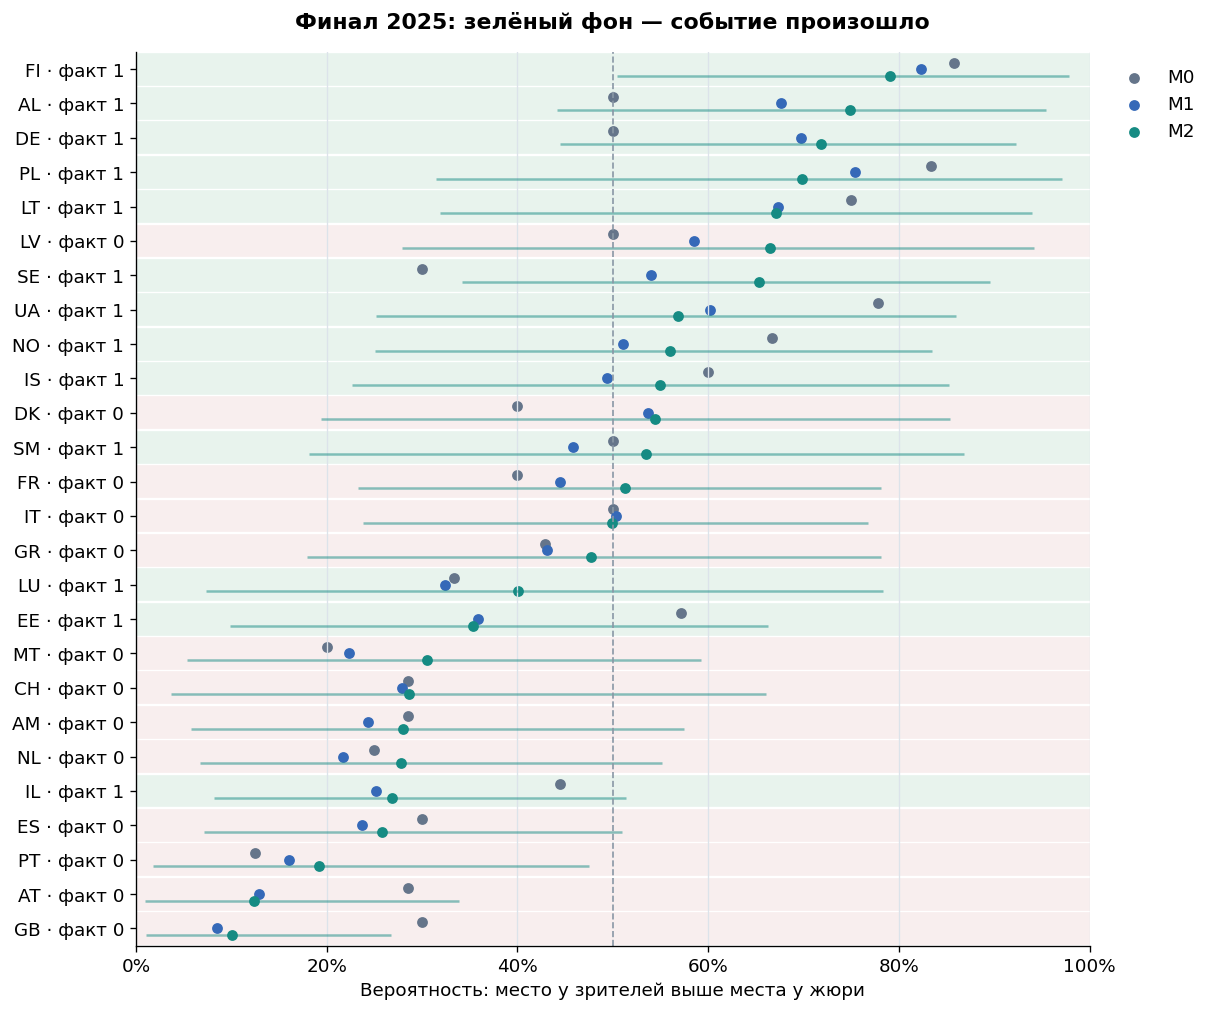

In [15]:
country_order = holdout_runs["M2"]["prediction"].sort_values("p", ascending=False).country.tolist()
actual = holdout_truth.set_index("country")[TARGET]
y = np.arange(len(country_order))
fig, ax = plt.subplots(figsize=(10, max(7, len(y)*0.32)), layout="constrained")
for j, country in enumerate(country_order):
    ax.axhspan(j-0.45, j+0.45, color="#E8F3ED" if actual[country] else "#F8EEEE", zorder=-2)
for i, model_id in enumerate(MODELS):
    p = holdout_runs[model_id]["prediction"].set_index("country").loc[country_order]
    if model_id == "M2":
        ax.hlines(y+(i-1)*0.19, p.p_q05, p.p_q95, color=COLORS[model_id], alpha=0.5, linewidth=1.5)
    ax.scatter(p.p, y+(i-1)*0.19, s=30, color=COLORS[model_id], label=model_id)
ax.axvline(0.5, color="#8997A5", linestyle="--", linewidth=1)
ax.set_yticks(y, [f"{c} · факт {int(actual[c])}" for c in country_order])
ax.set(xlim=(0, 1), ylim=(len(y)-0.5, -0.5),
       xlabel="Вероятность: место у зрителей выше места у жюри")
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="x", color="#DCE3EA")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("Финал 2025: зелёный фон — событие произошло", pad=14)
fig.savefig(OUTPUT_DIR / "forecast_2025.png", dpi=220, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "forecast_2025.pdf", bbox_inches="tight")
plt.show()


## 10. Калибровка и диагностика

Калибровка использует только прогнозы 2021–2024 и десять фиксированных интервалов,
как в HA1. Каждый конкурс получает одинаковый суммарный вес.
Trace plots показывают эффект одной страны и масштаб иерархии.


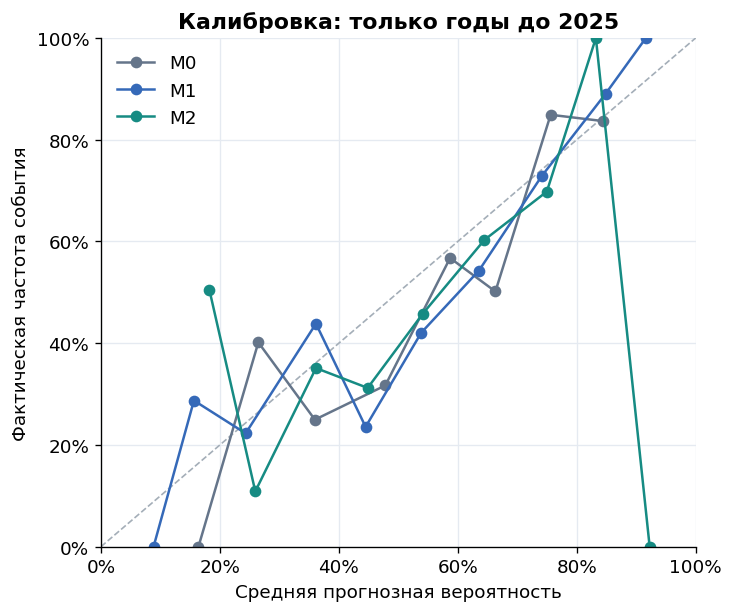

,model,year,train_end,passed,method,prior_concentration,prior_multiplier,train_start,rhat_max,ess_bulk_min,ess_tail_min,divergences,max_depth_hits,seconds,attempt
0,M0,2025,2024,True,exact_Beta_Bernoulli,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,M1,2025,2024,True,NaN,NaN,1.0,2016.0,1.005,2165.1866,2361.3218,0.0,0.0,25.6237,1.0
2,M2,2025,2024,True,NaN,NaN,1.0,2016.0,1.006,847.2215,1434.9444,0.0,0.0,31.6321,1.0


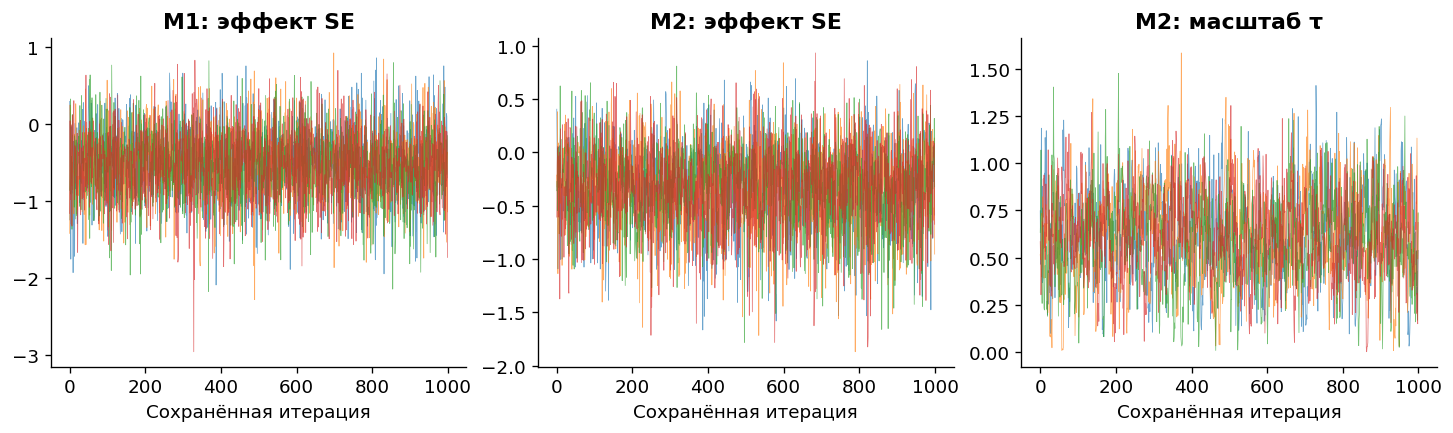

In [16]:
fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
ax.plot([0, 1], [0, 1], "--", color="#A4AEB8", linewidth=1)
calibration_tables = []
for model_id in MODELS:
    parts = []
    for year in DEV_YEARS:
        pred = development_runs[(year, model_id)]["prediction"]
        truth = development.loc[development.year.eq(year), ["year", "country", TARGET]]
        parts.append(pred.merge(truth, on=["year", "country"]).assign(weight=1/len(pred)))
    p = pd.concat(parts, ignore_index=True)
    p["bin"] = pd.cut(p.p, np.linspace(0, 1, 11), include_lowest=True, right=True)
    bins = pd.DataFrame([dict(model=model_id, bin=str(interval), n=len(g),
                              predicted=np.average(g.p, weights=g.weight),
                              observed=np.average(g[TARGET], weights=g.weight))
                         for interval, g in p.groupby("bin", observed=True)])
    calibration_tables.append(bins)
    ax.plot(bins.predicted, bins.observed, "o-", color=COLORS[model_id], label=model_id)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Средняя прогнозная вероятность",
       ylabel="Фактическая частота события", title="Калибровка: только годы до 2025")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(color="#E5EAF1")
ax.legend(frameon=False)
fig.savefig(OUTPUT_DIR / "calibration_development.png", dpi=180, bbox_inches="tight")
plt.show()
display(pd.DataFrame([r["diagnostic"] for r in holdout_runs.values()]))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), layout="constrained")
trace_country = "SE" if "SE" in holdout_runs["M1"]["fold"]["index"] else holdout_runs["M1"]["fold"]["countries"][0]
for ax, model_id in zip(axes[:2], ["M1", "M2"]):
    r = holdout_runs[model_id]
    j = r["fold"]["index"][trace_country]
    for chain in r["samples"]["a"][:, :, j]:
        ax.plot(chain, linewidth=0.45, alpha=0.65)
    ax.set(title=f"{model_id}: эффект {trace_country}", xlabel="Сохранённая итерация")
for chain in holdout_runs["M2"]["samples"]["tau"]:
    axes[2].plot(chain, linewidth=0.45, alpha=0.65)
axes[2].set(title="M2: масштаб τ", xlabel="Сохранённая итерация")
fig.savefig(OUTPUT_DIR / "posterior_traces.png", dpi=180, bbox_inches="tight")
plt.show()


## 11. Сохранение результатов

Сохраняем прогнозы, ошибки, priors, диагностику и posterior draws.
Коэффициенты интерпретируем как прогностические связи.
Сумма бинарных log scores не называется совместным прогнозом всего финала.
Отличия M2 от M1 оцениваем по результатам, а не по сложности модели.


In [17]:
pd.concat([r["prediction"] for r in development_runs.values()], ignore_index=True).to_csv(
    OUTPUT_DIR / "development_predictions.csv", index=False)
dev_metrics.to_csv(OUTPUT_DIR / "development_metrics_by_year.csv", index=False)
dev_summary.to_csv(OUTPUT_DIR / "development_summary.csv")
paired_comparisons.to_csv(OUTPUT_DIR / "paired_comparisons.csv", index=False)
predictions_2025.to_csv(OUTPUT_DIR / "predictions_2025.csv", index=False)
comparison_2025.to_csv(OUTPUT_DIR / "comparison_2025.csv", index=False)
holdout_metrics.to_csv(OUTPUT_DIR / "metrics_2025.csv")
pd.DataFrame(diagnostics).to_csv(OUTPUT_DIR / "diagnostics.csv", index=False)
prior_predictive.to_csv(OUTPUT_DIR / "prior_predictive.csv", index=False)
pd.concat(calibration_tables).to_csv(OUTPUT_DIR / "calibration.csv", index=False)
if sensitivity_rows:
    sensitivity.to_csv(OUTPUT_DIR / "prior_sensitivity_2024.csv", index=False)
pd.DataFrame({"mean": holdout_runs["M1"]["fold"]["mean"],
              "scale": holdout_runs["M1"]["fold"]["scale"]}).to_csv(OUTPUT_DIR / "training_scaler_2025.csv")
feature_effects = []
for model_id in ["M1", "M2"]:
    b = holdout_runs[model_id]["samples"]["beta"].reshape(-1, len(FEATURES))
    for j, feature in enumerate(FEATURES):
        feature_effects.append(dict(model=model_id, feature=feature, mean=b[:, j].mean(),
                                    q05=np.quantile(b[:, j], 0.05), q95=np.quantile(b[:, j], 0.95)))
pd.DataFrame(feature_effects).to_csv(OUTPUT_DIR / "feature_effects_2025.csv", index=False)
manifest = dict(task="B", experiment=EXPERIMENT, sheet=SHEET, features=FEATURES,
                target=TARGET, holdout=HOLDOUT_YEAR, development_test_years=DEV_YEARS,
                train_rule="year < test_year", seed=SEED, model_version=MODEL_VERSION,
                country_sd=COUNTRY_SD, beta_sd=BETA_SD, tau_sd=TAU_SD,
                chains=NUM_CHAINS, warmup=NUM_WARMUP, samples=NUM_SAMPLES,
                input_sha256=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
                versions=dict(numpyro=numpyro.__version__, jax=jax.__version__, arviz=az.__version__),
                market_snapshot_time="unknown_accepted" if EXPERIMENT=="market" else "not_used")
(OUTPUT_DIR / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
for newer, older in [("M1", "M0"), ("M2", "M1")]:
    pivot = dev_metrics.pivot(index="year", columns="model", values="brier")
    print(f"До 2025: Brier({newer}) − Brier({older}) = {(pivot[newer]-pivot[older]).mean():+.4f}.")
archive = shutil.make_archive(str(OUTPUT_DIR), "zip", OUTPUT_DIR)
print(f"Результаты: {OUTPUT_DIR.resolve()}\nАрхив: {archive}")


До 2025: Brier(M1) − Brier(M0) = +0.0210.
До 2025: Brier(M2) − Brier(M1) = +0.0036.
Результаты: /content/results_B/matched_core
Архив: /content/results_B/matched_core.zip


## Основа в материалах курса

Решённый HA1 (`four_rules`, `forecast_games`) — прогноз по истории отдельной команды;
HA3 (`gibbs`, устойчивый predictive log score) — Bayesian probit;
HA4 (`model`, NUTS) — нецентрированная иерархия.
Прогнозируем по posterior probabilities, а не по коэффициентам posterior mean.


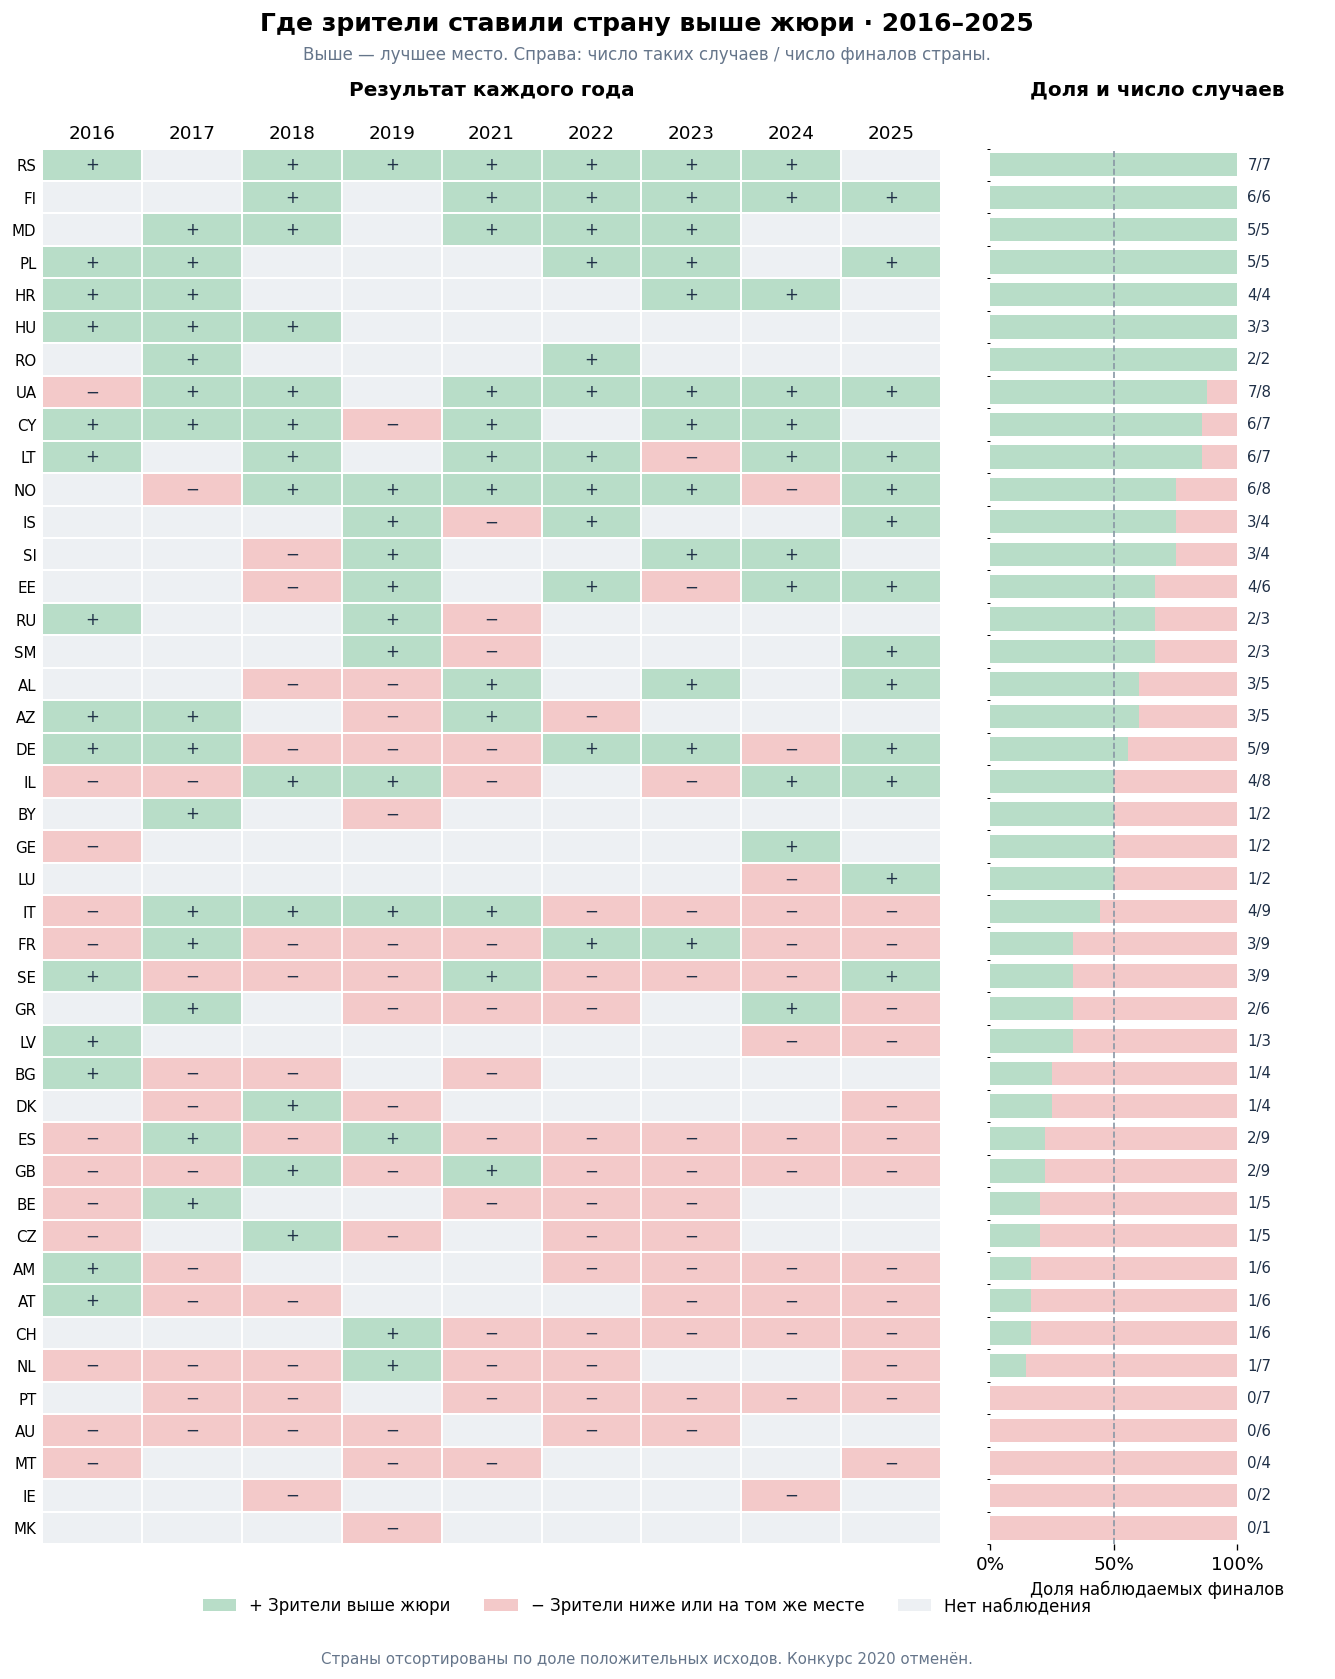

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
from pathlib import Path

target = "target_audience_above_jury"
df = raw[["year", "country", target]].copy()

assert not df.duplicated(["year", "country"]).any()
assert df[target].isin([0, 1]).all()

# Все страны сохраняются, включая страны с короткой историей.
stats = df.groupby("country")[target].agg(wins="sum", n="size")
stats["share"] = stats["wins"] / stats["n"]
stats = stats.sort_values(
    ["share", "n"], ascending=[False, False], kind="stable"
)

years = sorted(df.year.unique())
matrix = df.pivot(
    index="country", columns="year", values=target
).reindex(index=stats.index, columns=years)

values = matrix.to_numpy(float)

# 0 — нет наблюдения; 1 — зрители не выше; 2 — зрители выше.
colors = np.where(np.isnan(values), 0, values + 1)
GRAY, RED, GREEN = "#EDF0F3", "#F3C9C9", "#B8DDC8"
INK = "#203047"

fig, (ax, ax_share) = plt.subplots(
    1, 2,
    figsize=(12, max(8, len(stats) * 0.29 + 1.8)),
    gridspec_kw={"width_ratios": [3.5, 1.3]},
    sharey=True
)

ax.imshow(
    colors,
    cmap=ListedColormap([GRAY, RED, GREEN]),
    vmin=-0.5, vmax=2.5,
    aspect="auto", interpolation="nearest"
)

ax.set_xticks(range(len(years)), [str(y) for y in years])
ax.set_yticks(range(len(stats)), stats.index)
ax.tick_params(
    axis="x", top=True, labeltop=True,
    bottom=False, labelbottom=False, length=0
)
ax.tick_params(axis="y", length=0, labelsize=9)

# Границы ячеек.
ax.set_xticks(np.arange(-0.5, len(years), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(stats), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=1.2)
ax.tick_params(which="minor", bottom=False, left=False)

for row, col in np.argwhere(~np.isnan(values)):
    ax.text(
        col, row, "+" if values[row, col] == 1 else "−",
        ha="center", va="center", color=INK, fontsize=10
    )

ax.set_title("Результат каждого года", fontsize=12, pad=32)

# Справа — доля положительных исходов и размер истории.
y = np.arange(len(stats))
ax_share.barh(y, stats["share"], color=GREEN, height=0.72)
ax_share.barh(
    y, 1 - stats["share"],
    left=stats["share"], color=RED, height=0.72
)
ax_share.axvline(0.5, color="#8997A5", ls="--", lw=1)

for row, (_, s) in enumerate(stats.iterrows()):
    ax_share.text(
        1.04, row, f"{int(s['wins'])}/{int(s['n'])}",
        va="center", fontsize=9, color=INK
    )

ax_share.set_xlim(0, 1.35)
ax_share.set_xticks([0, 0.5, 1])
ax_share.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax_share.tick_params(axis="y", left=False, labelleft=False)
ax_share.set_title("Доля и число случаев", fontsize=12, pad=32)
ax_share.set_xlabel("Доля наблюдаемых финалов", fontsize=10)

for panel in (ax, ax_share):
    for spine in panel.spines.values():
        spine.set_visible(False)

fig.suptitle(
    f"Где зрители ставили страну выше жюри · {years[0]}–{years[-1]}",
    fontsize=15, fontweight="bold", y=0.98
)
fig.text(
    0.5, 0.952,
    "Выше — лучшее место. Справа: число таких случаев / число финалов страны.",
    ha="center", fontsize=10, color="#65758A"
)

fig.legend(
    handles=[
        Patch(facecolor=GREEN, label="+ Зрители выше жюри"),
        Patch(facecolor=RED, label="− Зрители ниже или на том же месте"),
        Patch(facecolor=GRAY, label="Нет наблюдения"),
    ],
    loc="lower center", bbox_to_anchor=(0.5, 0.035),
    ncol=3, frameon=False, fontsize=10
)
fig.text(
    0.5, 0.015,
    "Страны отсортированы по доле положительных исходов. Конкурс 2020 отменён.",
    ha="center", fontsize=9, color="#65758A"
)
fig.subplots_adjust(
    left=0.08, right=0.97, top=0.90, bottom=0.085, wspace=0.08
)

out = Path(globals().get("OUTPUT_DIR", "."))
out.mkdir(parents=True, exist_ok=True)
fig.savefig(out / "B_history_by_country.png", dpi=240, bbox_inches="tight")
fig.savefig(out / "B_history_by_country.pdf", bbox_inches="tight")
plt.show()